Volatilidade do 60/40: 9.6%
60/40: ações = 60% do dinheiro e 91.8% do risco
Cada real em ações traz 3x o risco de um real em títulos
  correlação 0.0: ações = 95.3% do risco
  correlação 0.1: ações = 93.5% do risco
  correlação 0.2: ações = 91.8% do risco
  correlação 0.3: ações = 90.2% do risco


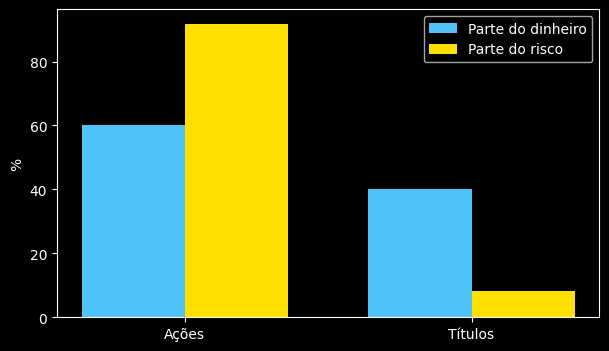

Pesos risk parity: ações 25%, títulos 75%
Risco: ações 50.0%, títulos 50.0%
Conferindo: 0.25 x 15 = 3.75 e 0.75 x 5 = 3.75
  correlação -0.3: ações = 50.0% do risco
  correlação +0.0: ações = 50.0% do risco
  correlação +0.5: ações = 50.0% do risco
  correlação +0.9: ações = 50.0% do risco


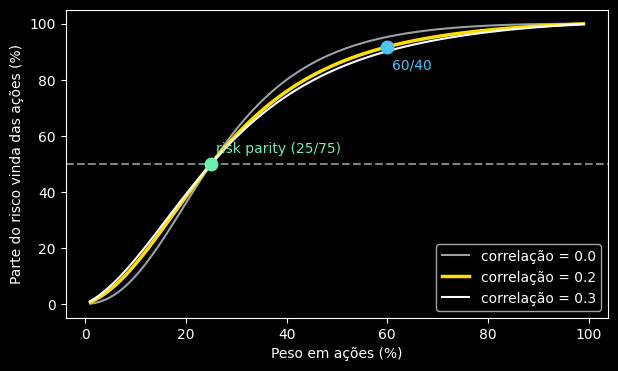

Pesos vol. inversa: [0.207 0.621 0.172] -> risco [0.375 0.3   0.325]
Pesos risk parity:  [0.186 0.643 0.172] -> risco [0.333 0.333 0.333]


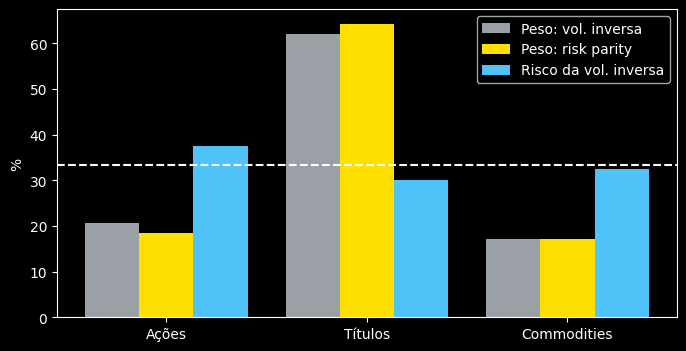

60/40:            retorno 7.4%  vol 9.6%  Sharpe 0.46
Risk parity:      retorno 6.0%  vol 5.8%  Sharpe 0.52
RP alavancado 1.65x: retorno 8.0%  vol 9.6%  Sharpe 0.52
60/40          mediana final    751 | pior ano mediano -11.8% | queda máx. mediana -13.9%
Risk parity    mediana final    551 | pior ano mediano -5.6% | queda máx. mediana -6.2%
RP alavancado  mediana final    886 | pior ano mediano -11.3% | queda máx. mediana -13.1%


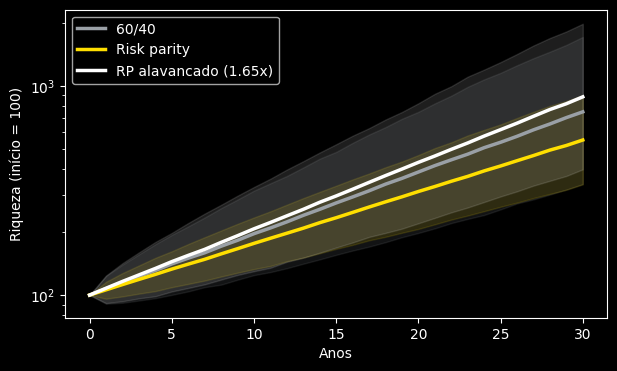

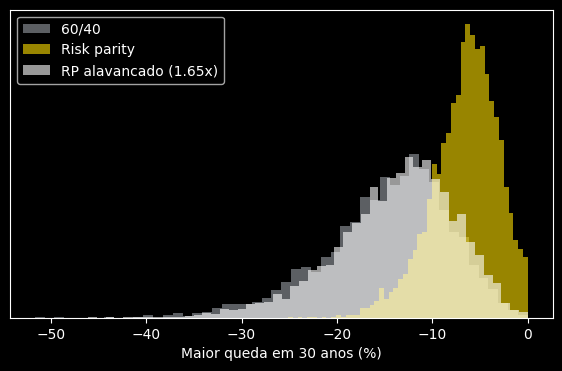

Cenário: ações -20%, títulos -15%
  60/40         : -18.0%
  Risk parity   : -16.2%
  RP alavancado : -28.8%


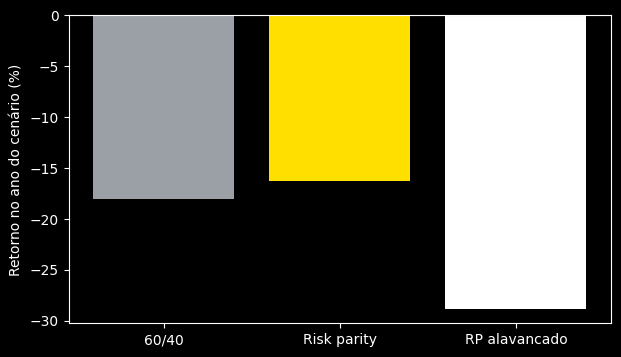

In [1]:
"""Quant Finance: Risk Parity (paridade de risco).

A Bridgewater lançou o All Weather em 1996. Os cenários são crescimento e
inflação, cada um acima ou abaixo do esperado, e o objetivo é ter a mesma
quantidade de risco em cada um deles. Risk parity espalha o risco por igual
entre os ativos, normalmente classes inteiras como ações, títulos e commodities.

Aqui: o 60/40 clássico concentra o risco nas ações, e o risk parity corrige isso
com pesos que dão a cada ativo a mesma contribuição para o risco total.

Todos os números são assumidos e os retornos são simulados, material educacional.
Mostra como o MÉTODO funciona, não o que os mercados reais vão pagar.

Como rodar:  python risk_parity.py     (gera 6 gráficos em graficos_risk_parity/)
Requer: numpy e matplotlib.
"""
import os

os.makedirs("graficos_risk_parity", exist_ok=True)

#Passo 1: parâmetros
import numpy as np

rng = np.random.default_rng(42)
vol_acoes = 0.15       # volatilidade das ações ao ano
vol_bonds = 0.05       # volatilidade dos títulos ao ano
corr = 0.2             # correlação ações x títulos
rf = 0.03              # taxa livre de risco (e custo de se endividar)
premio_acoes = 0.06    # retorno acima da taxa livre de risco
premio_bonds = 0.02

vols = np.array([vol_acoes, vol_bonds])
C = np.array([[1, corr], [corr, 1]])
cov = np.outer(vols, vols) * C
w_6040 = np.array([0.6, 0.4])

#Passo 2: variância, contribuição de cada ativo e pesos de volatilidade inversa
def variancia(w, cov):
    return w @ cov @ w

def risk_shares(w, cov):
    """Parte do risco total que cada ativo causa: w_i (Σw)_i / σ_p²."""
    return w * (cov @ w) / variancia(w, cov)

def pesos_vol_inversa(vols):
    """w_i = (1/σ_i) / Σ_j (1/σ_j). Os pesos somam 100%."""
    inv = 1 / vols
    return inv / inv.sum()

#Passo 3: o 60/40 e o risco escondido
rs = risk_shares(w_6040, cov)
print(f"Volatilidade do 60/40: {np.sqrt(variancia(w_6040, cov)):.1%}")
print(f"60/40: ações = {w_6040[0]:.0%} do dinheiro e {rs[0]:.1%} do risco")
print(f"Cada real em ações traz {vol_acoes / vol_bonds:.0f}x o risco de um real em títulos")
for c in (0.0, 0.1, 0.2, 0.3):
    cv = np.outer(vols, vols) * np.array([[1, c], [c, 1]])
    print(f"  correlação {c:.1f}: ações = {risk_shares(w_6040, cv)[0]:.1%} do risco")

#Gráfico 1: dinheiro contra risco no 60/40
import matplotlib.pyplot as plt
plt.style.use("dark_background")
amarelo = "#FFDF00"
azul = "#4FC3F7"

plt.figure(figsize=(7, 4))
x = np.arange(2)
plt.bar(x - 0.18, w_6040 * 100, 0.36, color=azul, label="Parte do dinheiro")
plt.bar(x + 0.18, rs * 100, 0.36, color=amarelo, label="Parte do risco")
plt.xticks(x, ["Ações", "Títulos"])
plt.ylabel("%")
plt.legend()
plt.savefig("graficos_risk_parity/grafico1_6040.png", dpi=200,
            bbox_inches="tight", facecolor="black")
plt.show()

#Passo 4: risk parity com dois ativos
w_rp = pesos_vol_inversa(vols)
rs_rp = risk_shares(w_rp, cov)
print(f"Pesos risk parity: ações {w_rp[0]:.0%}, títulos {w_rp[1]:.0%}")
print(f"Risco: ações {rs_rp[0]:.1%}, títulos {rs_rp[1]:.1%}")
print(f"Conferindo: 0.25 x 15 = {0.25 * 15:.2f} e 0.75 x 5 = {0.75 * 5:.2f}")
for c in (-0.3, 0.0, 0.5, 0.9):
    cv = np.outer(vols, vols) * np.array([[1, c], [c, 1]])
    print(f"  correlação {c:+.1f}: ações = {risk_shares(w_rp, cv)[0]:.1%} do risco")

#Gráfico 2: fatia de risco das ações conforme o peso em ações
pesos = np.linspace(0.01, 0.99, 99)
plt.figure(figsize=(7, 4))
for c, cor in [(0.0, "#9AA0A6"), (0.2, amarelo), (0.3, "white")]:
    cv = np.outer(vols, vols) * np.array([[1, c], [c, 1]])
    fatia = [risk_shares(np.array([p, 1 - p]), cv)[0] * 100 for p in pesos]
    plt.plot(pesos * 100, fatia, color=cor, lw=2.5 if c == 0.2 else 1.5,
             label=f"correlação = {c}")
plt.axhline(50, color="gray", ls="--")
plt.plot([60], [rs[0] * 100], "o", color=azul, ms=9)
plt.plot([25], [50], "o", color="#69F0AE", ms=9)
plt.text(61, rs[0] * 100 - 8, "60/40", color=azul)
plt.text(26, 54, "risk parity (25/75)", color="#69F0AE")
plt.xlabel("Peso em ações (%)")
plt.ylabel("Parte do risco vinda das ações (%)")
plt.legend(loc="lower right")
plt.savefig("graficos_risk_parity/grafico2_fatia_risco.png", dpi=200,
            bbox_inches="tight", facecolor="black")
plt.show()

#Passo 5: com três ativos, risk parity completo
# ações, títulos e commodities (números assumidos)
nomes3 = ["Ações", "Títulos", "Commodities"]
vols3 = np.array([0.15, 0.05, 0.18])
C3 = np.array([[1.0, 0.2, 0.3],
               [0.2, 1.0, 0.0],
               [0.3, 0.0, 1.0]])
cov3 = np.outer(vols3, vols3) * C3

def pesos_risk_parity(cov, passos=2000):
    """Resolve pesos com contribuições iguais de risco, por iteração."""
    n = len(cov)
    w = np.ones(n) / n
    for _ in range(passos):
        novo = 1 / (cov @ w)
        novo = novo / novo.sum()
        w = 0.5 * w + 0.5 * novo
    return w

w3_iv = pesos_vol_inversa(vols3)
w3_rp = pesos_risk_parity(cov3)
print("Pesos vol. inversa:", np.round(w3_iv, 3), "-> risco", np.round(risk_shares(w3_iv, cov3), 3))
print("Pesos risk parity: ", np.round(w3_rp, 3), "-> risco", np.round(risk_shares(w3_rp, cov3), 3))

#Gráfico 3: a vol. inversa deixa de ser exata
plt.figure(figsize=(8, 4))
x = np.arange(3)
plt.bar(x - 0.27, w3_iv * 100, 0.27, color="#9AA0A6", label="Peso: vol. inversa")
plt.bar(x, w3_rp * 100, 0.27, color=amarelo, label="Peso: risk parity")
plt.bar(x + 0.27, risk_shares(w3_iv, cov3) * 100, 0.27, color=azul,
        label="Risco da vol. inversa")
plt.axhline(100 / 3, color="white", ls="--")
plt.xticks(x, nomes3)
plt.ylabel("%")
plt.legend()
plt.savefig("graficos_risk_parity/grafico3_tres_ativos.png", dpi=200,
            bbox_inches="tight", facecolor="black")
plt.show()

#Passo 6: o preço da calma e a alavancagem
mu_exc = np.array([premio_acoes, premio_bonds])

def resumo(w, alav=1.0):
    exc = alav * (w @ mu_exc)
    vol = alav * np.sqrt(variancia(w, cov))
    return rf + exc, vol, exc / vol

ret_6040, vol_6040, sh_6040 = resumo(w_6040)
ret_rp, vol_rp, sh_rp = resumo(w_rp)
alav = vol_6040 / vol_rp
ret_lev, vol_lev, sh_lev = resumo(w_rp, alav)
print(f"60/40:            retorno {ret_6040:.1%}  vol {vol_6040:.1%}  Sharpe {sh_6040:.2f}")
print(f"Risk parity:      retorno {ret_rp:.1%}  vol {vol_rp:.1%}  Sharpe {sh_rp:.2f}")
print(f"RP alavancado {alav:.2f}x: retorno {ret_lev:.1%}  vol {vol_lev:.1%}  Sharpe {sh_lev:.2f}")

#Passo 7: 5.000 vidas de 30 anos
anos, n_vidas = 30, 5000
L = np.linalg.cholesky(cov)
medias = np.array([rf + premio_acoes, rf + premio_bonds])
Z = rng.standard_normal((n_vidas, anos, 2))
ret = medias + Z @ L.T              # retorno anual de cada ativo

def carteira(w, alav=1.0):
    exc = (ret - rf) @ w
    return rf + alav * exc          # o excesso é escalado, o resto é custo do dinheiro

r_6040 = carteira(w_6040)
r_rp = carteira(w_rp)
r_lev = carteira(w_rp, alav)

def cresce(r):
    return 100 * np.cumprod(1 + r, axis=1)

W = {"60/40": cresce(r_6040), "Risk parity": cresce(r_rp),
     f"RP alavancado ({alav:.2f}x)": cresce(r_lev)}

def max_dd(w):
    pico = np.maximum.accumulate(np.c_[np.full(len(w), 100.0), w], axis=1)[:, 1:]
    return (w / pico - 1).min(axis=1)

for nome, r, w in [("60/40", r_6040, W["60/40"]), ("Risk parity", r_rp, W["Risk parity"]),
                   ("RP alavancado", r_lev, W[f"RP alavancado ({alav:.2f}x)"])]:
    print(f"{nome:<14} mediana final {np.median(w[:, -1]):>6.0f} | pior ano mediano "
          f"{np.median(r.min(axis=1)):.1%} | queda máx. mediana {np.median(max_dd(w)):.1%}")

#Gráfico 4: riqueza mediana e faixa de 5% a 95%
t = np.arange(anos + 1)
plt.figure(figsize=(7, 4))
for (nome, w), cor in zip(W.items(), ["#9AA0A6", amarelo, "white"]):
    med = np.r_[100, np.median(w, axis=0)]
    p5 = np.r_[100, np.percentile(w, 5, axis=0)]
    p95 = np.r_[100, np.percentile(w, 95, axis=0)]
    plt.plot(t, med, color=cor, lw=2.5, label=nome)
    plt.fill_between(t, p5, p95, color=cor, alpha=0.12)
plt.yscale("log")
plt.xlabel("Anos")
plt.ylabel("Riqueza (início = 100)")
plt.legend()
plt.savefig("graficos_risk_parity/grafico4_riqueza.png", dpi=200,
            bbox_inches="tight", facecolor="black")
plt.show()

#Gráfico 5: a queda máxima em cada vida
plt.figure(figsize=(7, 4))
for (nome, w), cor in zip(W.items(), ["#9AA0A6", amarelo, "white"]):
    plt.hist(max_dd(w) * 100, bins=50, alpha=0.6, color=cor, label=nome, density=True)
plt.xlabel("Maior queda em 30 anos (%)")
plt.yticks([])
plt.legend()
plt.savefig("graficos_risk_parity/grafico5_queda_maxima.png", dpi=200,
            bbox_inches="tight", facecolor="black")
plt.show()

#Passo 8: quando ações e títulos caem juntos
# cenário hipotético, não é dado histórico
ch_acoes, ch_bonds = -0.20, -0.15
cen = np.array([ch_acoes, ch_bonds])
perdas = {
    "60/40": w_6040 @ cen,
    "Risk parity": w_rp @ cen,
    "RP alavancado": rf + alav * (w_rp @ (cen - rf)),
}
print(f"Cenário: ações {ch_acoes:.0%}, títulos {ch_bonds:.0%}")
for nome, p in perdas.items():
    print(f"  {nome:<14}: {p:.1%}")

#Gráfico 6: o balanço não protege
plt.figure(figsize=(7, 4))
plt.bar(list(perdas), [p * 100 for p in perdas.values()],
        color=["#9AA0A6", amarelo, "white"])
plt.axhline(0, color="gray")
plt.ylabel("Retorno no ano do cenário (%)")
plt.savefig("graficos_risk_parity/grafico6_estresse.png", dpi=200,
            bbox_inches="tight", facecolor="black")
plt.show()